<a href="https://colab.research.google.com/github/billyccw/ARIN5101-Project/blob/main/ARIN5101_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Team Information**
Group: 2

Member 1: Chan Chi Wai

Member 2:

Member 3:

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from google.colab import drive
import os
import time
from torchvision import datasets, transforms
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score
from itertools import product

# set data saving point
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/ARIN5101/', exist_ok=True)

# seed setting for reproducibility
seed = 42

# GPU setting
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

Mounted at /content/drive
cpu


In [5]:
'''
Helper functions
'''

# this function set seed for reproduceability, better call before each training
def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

# this function is referenced to: https://discuss.pytorch.org/t/how-to-do-a-stratified-split/62290/5
# It is to turn training data into training set and validation set at fixed ratio for each class
def stratified_split(train_data, val_size, random_seed):
  labels = np.asarray(train_data.targets)
  train_idx, validation_idx = train_test_split(np.arange(len(train_data)),
                                                test_size=val_size,
                                                random_state=random_seed,
                                                shuffle=True,
                                                stratify=labels)
  # Subset dataset for train and val
  train_dataset = Subset(train_data, train_idx)
  validation_dataset = Subset(train_data, validation_idx)
  return train_dataset, validation_dataset

# this function trains and returns a model, it also saves the resulting training/validation loss and accuracy in csv file
# name param is to set name of resulting csv file.
def train(model, loss_fn, optimizer, train_loader, val_loader, name, epochs=20):
  model_loss = {"train": [], "val": []} # each list store loss of each epoch in training and validation respectively
  model_acc = {"train": [], "val": []}
  for epoch in range(epochs):
      train_loss, train_correct, train_total, val_loss, val_correct, val_total = 0, 0, 0, 0, 0, 0
      model.train()
      for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        p = model(X_batch)
        loss = loss_fn(p, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # performance calculation
        train_loss += loss.item() * y_batch.shape[0]
        y_hat = p.argmax(1)
        train_correct += (y_hat == y_batch).sum().item()
        train_total += y_batch.shape[0]
      model_loss["train"].append(train_loss / train_total)
      model_acc["train"].append(train_correct / train_total)

      # validation
      model.eval()
      with torch.no_grad():
        for X_batch, y_batch in val_loader:
          X_batch, y_batch = X_batch.to(device), y_batch.to(device)
          p = model(X_batch)
          loss = loss_fn(p, y_batch)
          # performance calculation
          val_loss += loss.item() * y_batch.shape[0]
          y_hat = p.argmax(1)
          val_correct += (y_hat == y_batch).sum().item()
          val_total += y_batch.shape[0]
      model_loss["val"].append(val_loss / val_total)
      model_acc["val"].append(val_correct / val_total)
      print(f"Epoch {epoch+1}: Training loss = {train_loss / train_total}, accuracy = {train_correct / train_total}; Validation loss = {val_loss / val_total}, accuracy = {val_correct / val_total}")

  # write loss and acc to csv file for future visualization
  df = pd.DataFrame({"train_loss": model_loss["train"], "train_acc": model_acc["train"], "val_loss": model_loss["val"], "val_acc": model_acc["val"]})
  save_path = '/content/drive/MyDrive/ARIN5101/train_stats'
  os.makedirs(save_path, exist_ok=True)
  df.to_csv(f'{save_path}/{name}_train_stats.csv', index=False, encoding="utf-8-sig")
  print(f"Saved statistics of training to '{save_path}/{name}_train_stats.csv'")
  return model

# this function predicts on testing set and saves resulting predictions and ground-truths to csv file
# name param is to set name of resulting csv file.
def test(model, test_loader, name):
  model.eval()
  all_preds = []
  all_labels = []
  with torch.no_grad():
    for X_batch, y_batch in test_loader:
      X_batch = X_batch.to(device)
      preds = model(X_batch).argmax(dim=1).cpu().numpy()
      all_preds.extend(preds)
      all_labels.extend(y_batch.numpy())
  df_pred = pd.DataFrame({
          "prediction": all_preds,
          "actual": all_labels
  })

  save_path = '/content/drive/MyDrive/ARIN5101/predictions'
  os.makedirs(save_path, exist_ok=True)
  df_pred.to_csv(f'{save_path}/{name}_predictions.csv', index=False, encoding="utf-8-sig")
  print(f"Saved {len(df_pred)} predictions to '{save_path}/{name}_predictions.csv'")

# this function reads and returns the train stats from csv
def read_train_stats(name):
  save_path = '/content/drive/MyDrive/ARIN5101/train_stats'
  df = pd.read_csv(f'{save_path}/{name}_train_stats.csv')
  return df['train_loss'], df['train_acc'], df['val_loss'], df['val_acc']

# this function reads and returns the testing results from csv
def read_test_results(name):
  save_path = '/content/drive/MyDrive/ARIN5101/predictions'
  df = pd.read_csv(f'{save_path}/{name}_predictions.csv')
  return df["actual"], df['prediction']

set_seed(seed)


# **Dataset Loading**

## Dataset description
• Basic description, distributions and samples

The dataset adopted in this project is a full set of CIFAR-100. As stated on the official website (https://cave.cs.toronto.edu/kriz/cifar.html), CIFAR-100 consists of 100 classes grouped into 20 superclasses. These classes cover a wide variety of objects, including animals, plants, furniture, vehicles, and natural scenes, among others. Each image is in RGB format (3 color channels) with a size of 32 x 32 pixels. The total number of images in the training and test sets is 50,000 and 10,000, respectively, where each class contributes exactly 500 training images and 100 test images. The statistics of the class distribution can be seen in Figure 1, and a sample image from each class is visualized in Figure 2.

In [6]:
# Download the dataset, direct load existing dataset in root if have
train_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=False, download=True, transform=transforms.ToTensor())
print(train_data)
print(test_data)
print(f"Shape of an image: {train_data[0][0].shape}")

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/ARIN5101/
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset CIFAR100
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/ARIN5101/
    Split: Test
    StandardTransform
Transform: ToTensor()
Shape of an image: torch.Size([3, 32, 32])


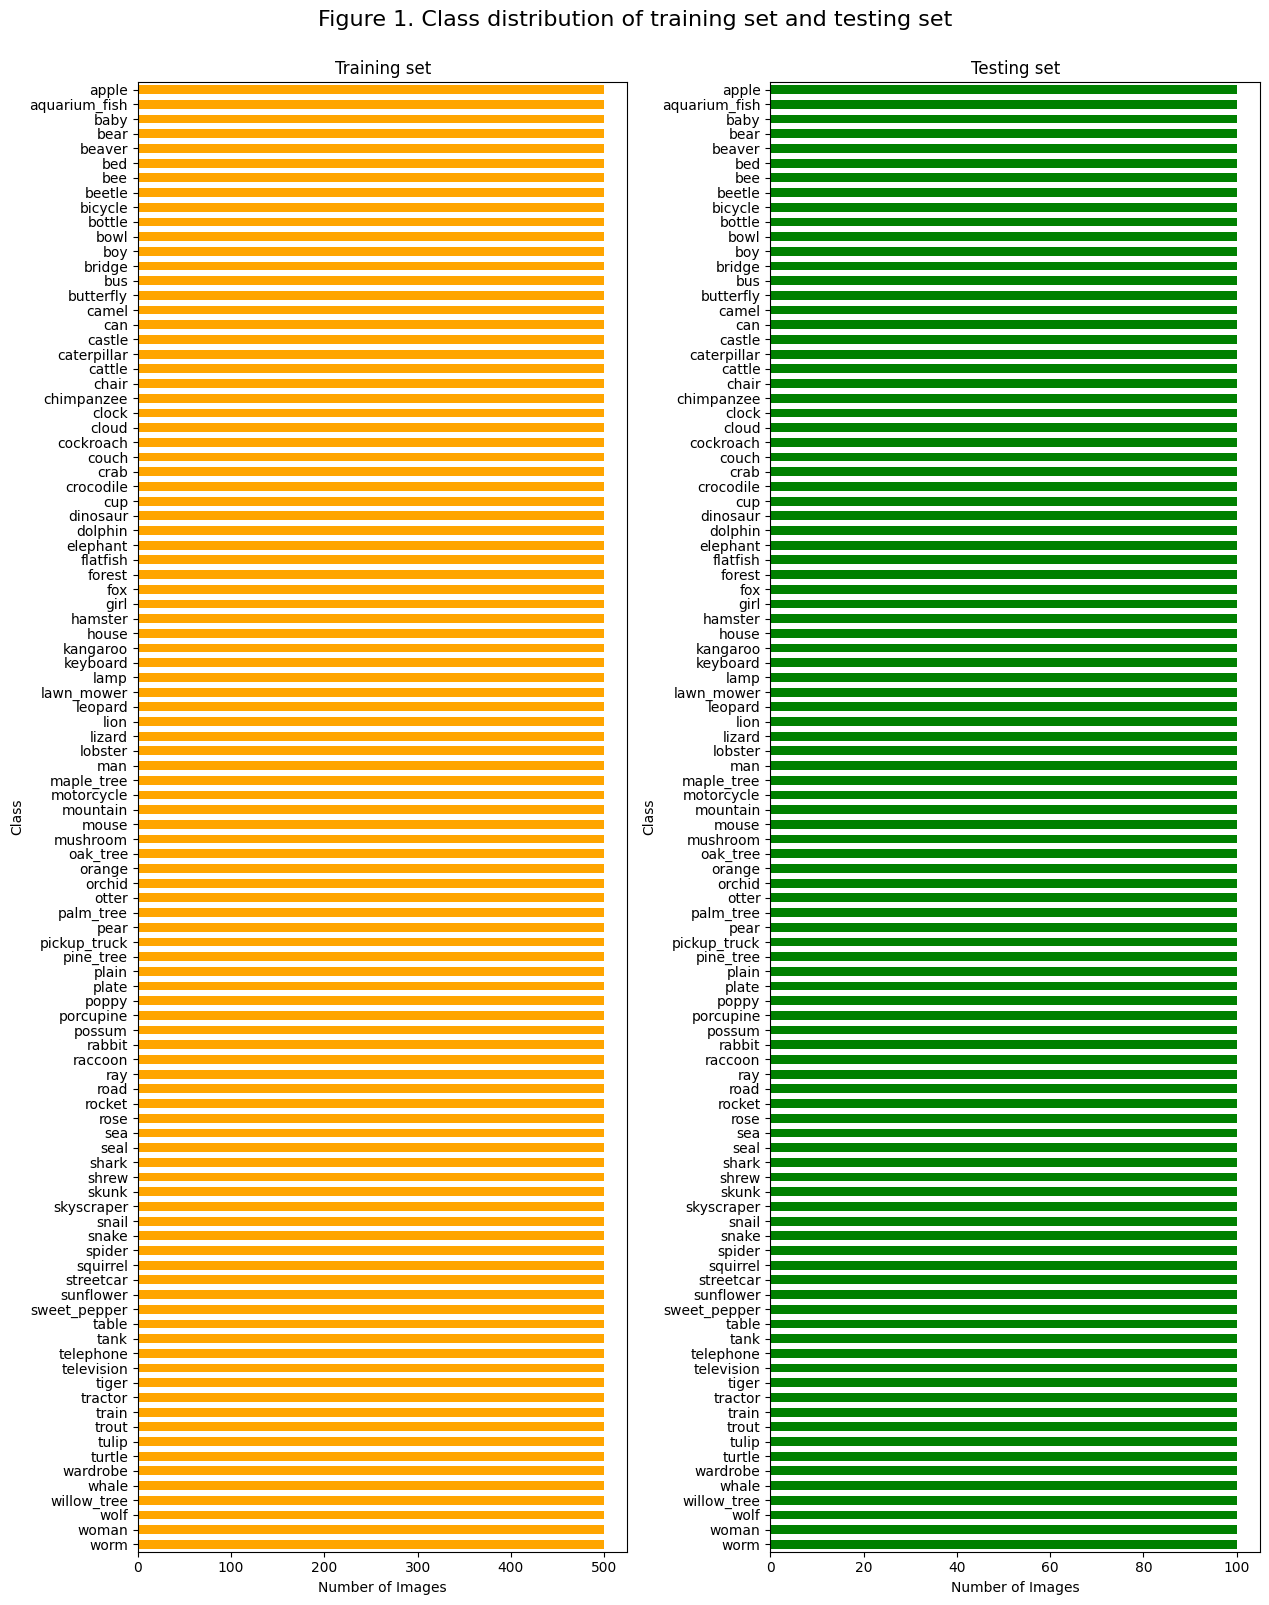

In [7]:
# visualize class distributions
y_train = [item[1] for item in train_data]
y_test = [item[1] for item in test_data]
y_train_freq = Counter(y_train)
y_test_freq = Counter(y_test)
sorted_y_train_freq = {k: v for k, v in sorted(y_train_freq.items(), key=lambda item: item[0])}
sorted_y_test_freq = {k: v for k, v in sorted(y_test_freq.items(), key=lambda item: item[0])}

plt.figure(figsize=(12.8, 16))
plt.suptitle(
    "Figure 1. Class distribution of training set and testing set",
    fontsize=16,
    y=1.,
)
plt.subplot(1, 2, 1)
plt.barh(train_data.classes, sorted_y_train_freq.values(), height=0.6, color="orange")
plt.ylim(-0.5, len(train_data.classes) - 0.5)
plt.gca().invert_yaxis()
plt.title("Training set")
plt.ylabel("Class")
plt.xlabel("Number of Images")
plt.subplot(1, 2, 2)
plt.barh(test_data.classes, sorted_y_test_freq.values(), height=0.6, color="green")
plt.ylim(-0.5, len(test_data.classes) - 0.5)
plt.gca().invert_yaxis()
plt.title("Testing set")
plt.ylabel("Class")
plt.xlabel("Number of Images")
plt.tight_layout()
plt.show()

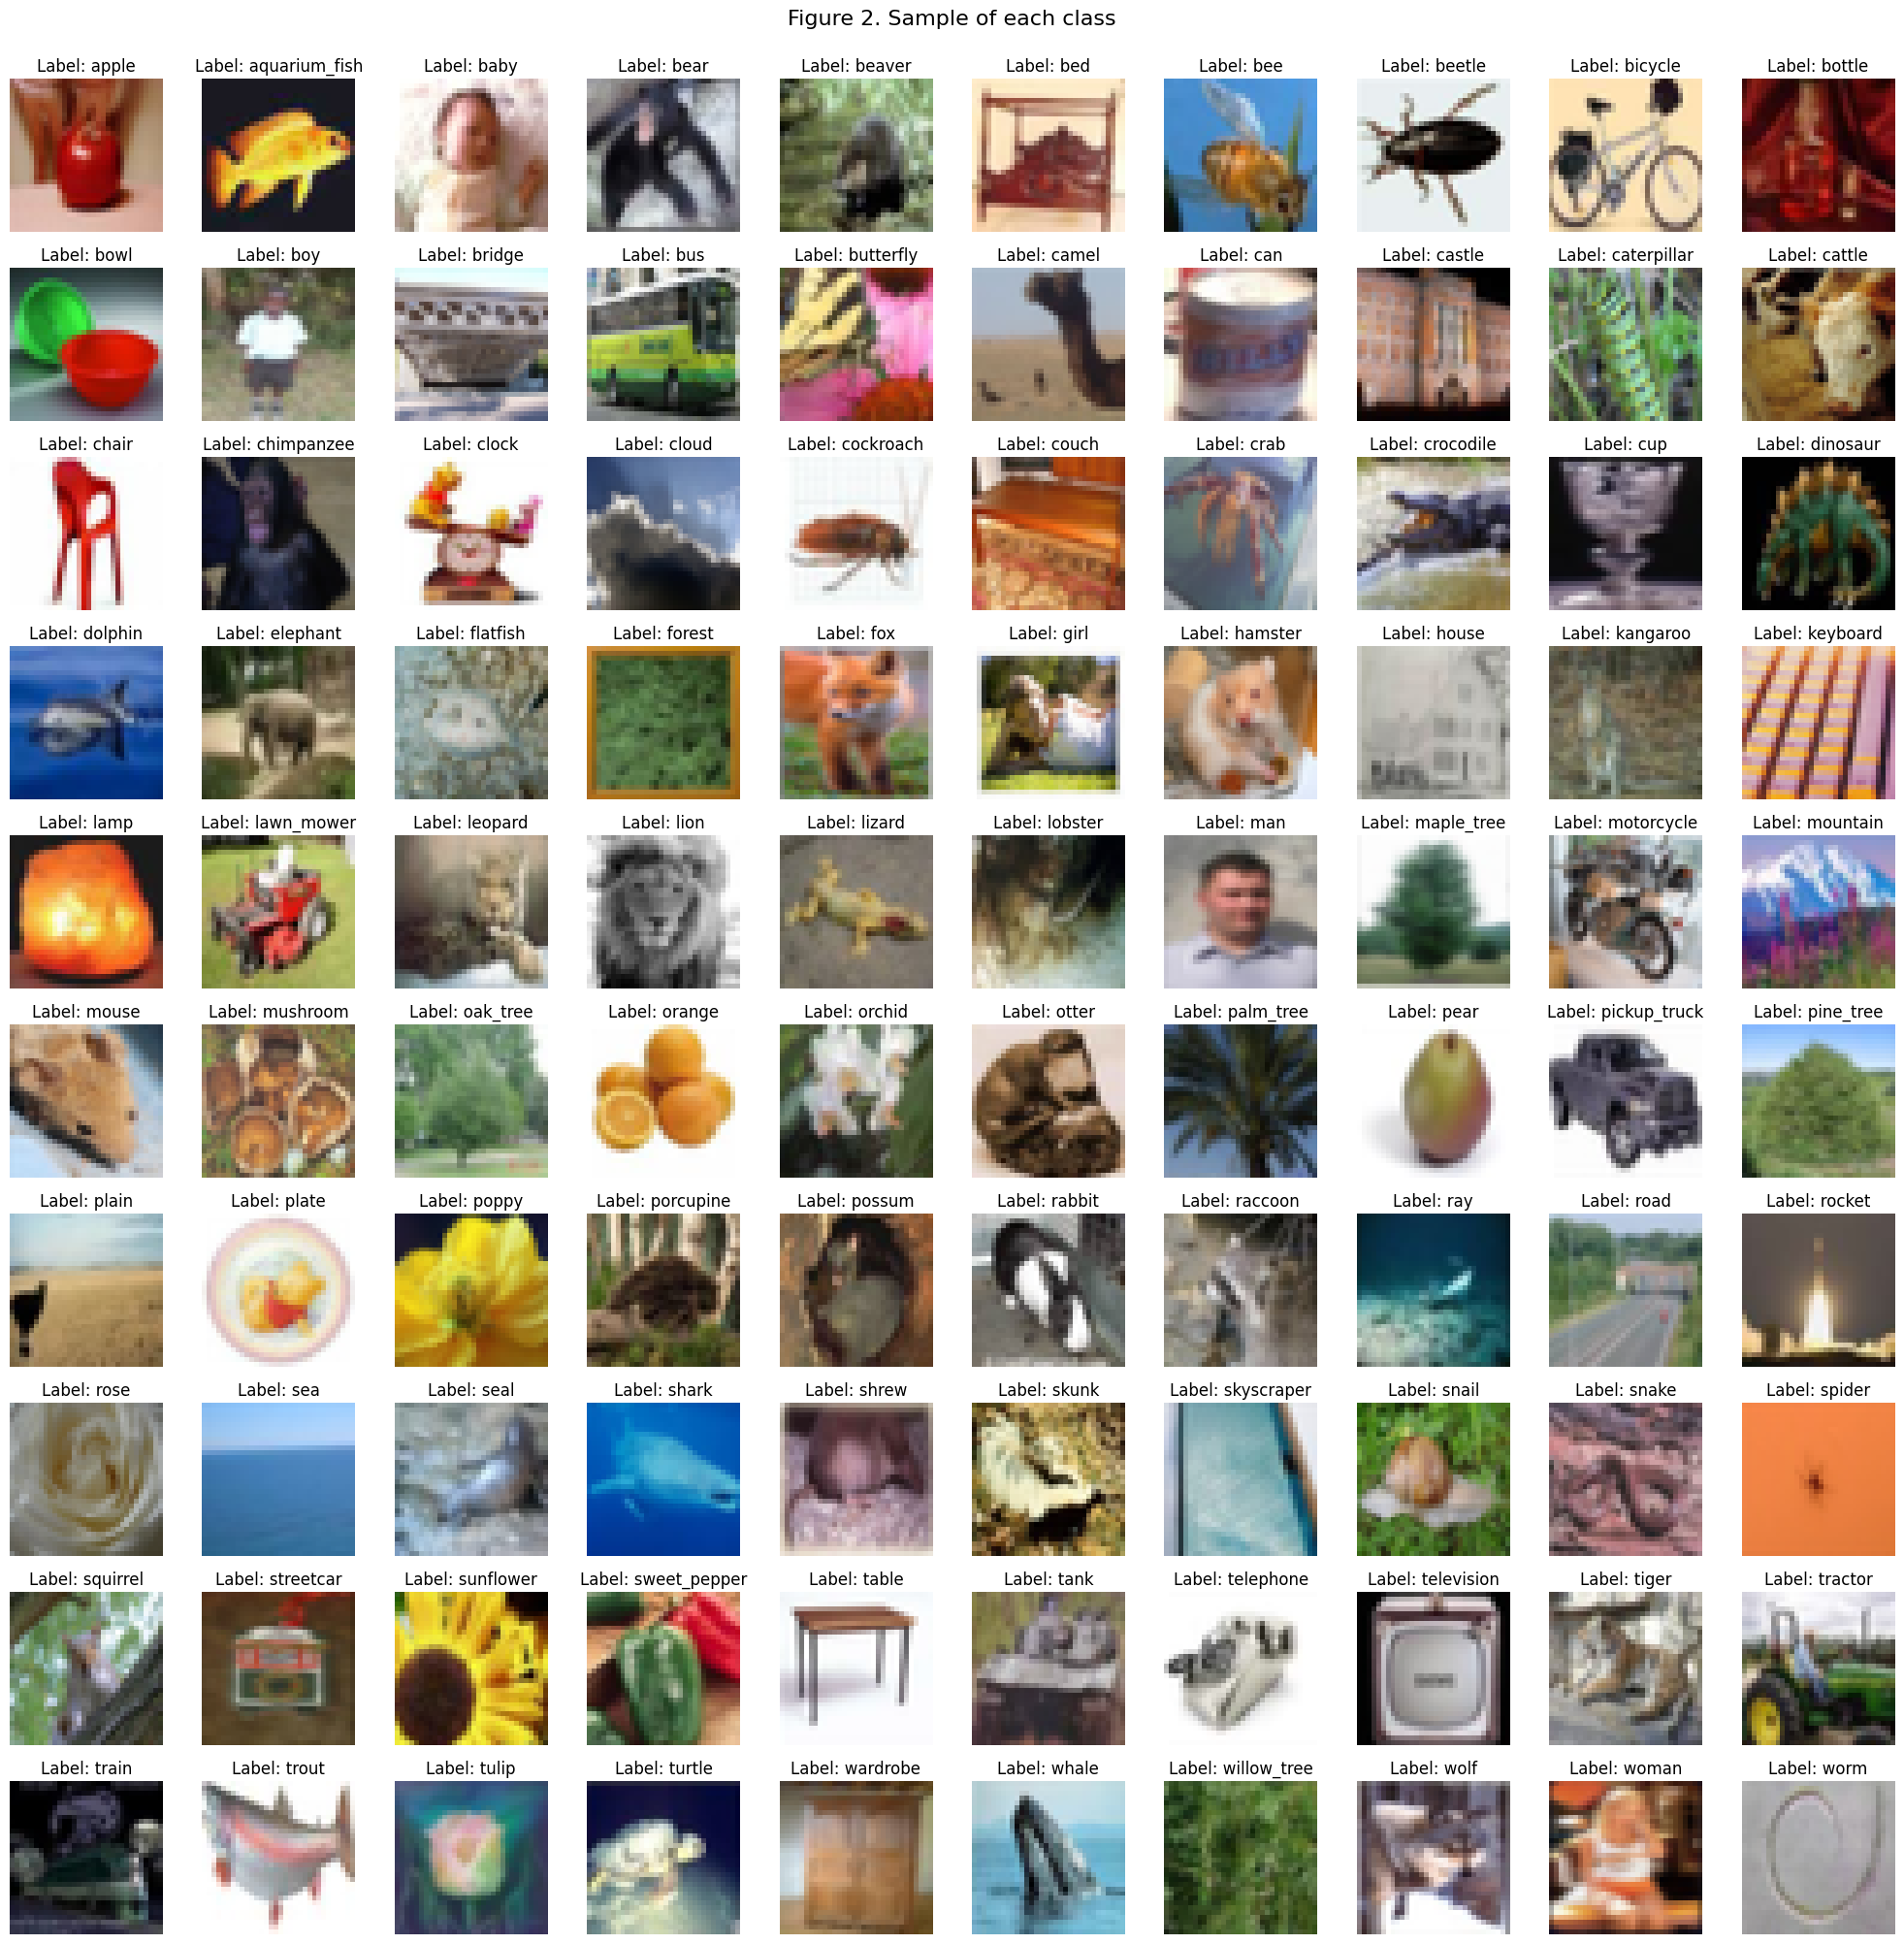

In [6]:
# sample and visualize each class
class_to_indices = {i: [] for i in range(100)}
for img_idx, label in enumerate(train_data.targets):
    class_to_indices[label].append(img_idx)

plt.figure(figsize=(20, 20))
plt.suptitle(
    "Figure 2. Sample of each class",
    fontsize=16,
    y=1.,
)
for idx, name in enumerate(train_data.classes):
  plt.subplot(10, 10, idx+1)
  available_indices = class_to_indices[idx]
  random_index = random.choice(available_indices)
  image = train_data[random_index][0]
  plt.imshow(image.numpy().transpose(1, 2, 0))
  plt.title(f"Label: {name}")
  plt.axis("off")
plt.tight_layout()
plt.show()

# **Dataset Splitting and Preprocessing**

## Training setup and validation strategy
• Dataset splitting strategy

This project further splits the original training set into training and validation sets at a 4:1 ratio, resulting in 40,000 images in the training set and 10,000 images in the validation set. This aligns the sizes of the validation and test sets. Moreover, the partition utilizes the stratified splitting method from the scikit-learn module to ensure that every class maintains the same training-to-validation ratio.

In [8]:
# splitting
splitted_train_data, splitted_val_data = stratified_split(train_data, val_size=0.2, random_seed=seed)
print(len(splitted_train_data), len(splitted_val_data))

# compute mean and std for standardization
total_pixels_per_channel = len(splitted_train_data) * splitted_train_data[0][0].shape[1] * splitted_train_data[0][0].shape[2]
mean = torch.tensor([0.0, 0.0, 0.0])
std = torch.tensor([0.0, 0.0, 0.0])
for image, _ in splitted_train_data:
  for i in range(3):
    mean[i] += image[i].sum()
    std[i] += (image[i]**2).sum()

# use formula sum(x-mean)^2 = sum(x^2) - (sum(x))^2/n
for i in range(3):
  std[i] -= mean[i]**2 / total_pixels_per_channel
  std[i] /= total_pixels_per_channel
  std[i] **= 0.5
  mean[i] /= total_pixels_per_channel
print(mean, std)

transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

# load and split data again with the standardization preprocessing
train_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=True, download=True, transform=transform)
test_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=False, download=True, transform=transform)
splitted_train_data, splitted_val_data = stratified_split(train_data, val_size=0.2, random_seed=seed)

40000 10000
tensor([0.5071, 0.4863, 0.4404]) tensor([0.2673, 0.2564, 0.2761])


# **Baseline CNN Architecture**

## Basic illustration
The default baseline CNN consists of two convolutional blocks followed by a fully connected classifier. Each convolutional block contains a Conv2d layer with kernel size = 3 and padding = 1, which keeps the spatial dimensions (H, W) unchanged within each convolution, followed by ReLU activation and a max pooling that halves the spatial dimensions.
<br></br>
The output channels of the first convolutional layer is 32 in the default setting, while each further convolutional layer would double the channels.
<br></br>
After the convolutional blocks, the feature map is flattened into a 1D vector and passed to a fully connected classifier with one hidden layer of 128 units followed by ReLU. The output layer has num_class units producing raw logits; no softmax is applied explicitly because nn.CrossEntropyLoss incorporates it internally.
<br></br>
Note that the baseline cnn is trained with 20 epochs, with batch size of 128 and learning rate of 0.001.

In [8]:
# Input param explaination
"""
in_channel: number of channel of input image
in_size: height/width size of input image
num_class: number of class in dataset
conv_layer_depth: depth of first convolution layer -> need to be tuned
hidden_layer_size: Hidden layer size -> need to be tuned
extra_conv: bool value indicating whether a third convolutional layer should be added
"""
class baselineCNN(nn.Module):
  def __init__(self, in_channel, in_size, num_class, conv_layer_depth=32, hidden_layer_size=128, extra_conv: bool = False):
    super().__init__()
    self.extra_conv = extra_conv
    self.conv1 = nn.Conv2d(in_channels=in_channel, out_channels = conv_layer_depth, kernel_size=3, padding=1)
    self.relu1 = nn.ReLU()
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = nn.Conv2d(in_channels=conv_layer_depth, out_channels = conv_layer_depth*2, kernel_size=3, padding=1)
    self.relu2 = nn.ReLU()
    self.pool2 = nn.MaxPool2d(2)
    if extra_conv:
      self.conv3 = nn.Conv2d(in_channels=conv_layer_depth*2, out_channels = conv_layer_depth*4, kernel_size=3, padding=1)
      self.relu3 = nn.ReLU()
      self.pool3 = nn.MaxPool2d(2)
    self.flatten = nn.Flatten()
    final_img_size = in_size // (2**(2+extra_conv))
    final_output_channel = conv_layer_depth * (4 if extra_conv else 2)
    self.linear1 = nn.Linear(final_img_size * final_img_size * final_output_channel, hidden_layer_size)
    self.relu_fc = nn.ReLU()
    self.linear2 = nn.Linear(hidden_layer_size, num_class)

  def forward(self, x):
    x = self.pool1(self.relu1(self.conv1(x)))
    x = self.pool2(self.relu2(self.conv2(x)))
    if self.extra_conv:
      x = self.pool3(self.relu3(self.conv3(x)))
    x = self.flatten(x)
    x = self.relu_fc(self.linear1(x))
    x = self.linear2(x)
    return x

batch_size = 128

In [13]:
# Train and validation
set_seed(seed)
g = torch.Generator().manual_seed(seed)

train_loader = DataLoader(splitted_train_data, batch_size=batch_size, shuffle=True, generator=g)
val_loader   = DataLoader(splitted_val_data, batch_size=batch_size, shuffle=False)

img_shape = train_data[0][0].shape
baseCNN_model = baselineCNN(in_channel=img_shape[0], in_size=img_shape[1], num_class=len(train_data.classes)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseCNN_model.parameters(), lr=0.001)

start = time.time()
baseCNN_model = train(baseCNN_model, loss_fn, optimizer, train_loader, val_loader, "baselineCNN")

# save the model so that we do not need to train again
save_path = '/content/drive/MyDrive/ARIN5101/models'
os.makedirs(save_path, exist_ok=True)
torch.save(baseCNN_model.state_dict(), f"{save_path}/baseline_CNN.pth")

print(f"total time spent to train and save a model: {time.time()-start}s")

Epoch 1: Training loss = 3.7349110153198244, accuracy = 0.13815; Validation loss = 3.263001471328735, accuracy = 0.2166
Epoch 2: Training loss = 2.9799248023986817, accuracy = 0.2682; Validation loss = 2.859534958267212, accuracy = 0.2936
Epoch 3: Training loss = 2.634524959564209, accuracy = 0.337475; Validation loss = 2.6905334201812745, accuracy = 0.3274
Epoch 4: Training loss = 2.391507992553711, accuracy = 0.3899; Validation loss = 2.640729357147217, accuracy = 0.343
Epoch 5: Training loss = 2.208955402755737, accuracy = 0.4254; Validation loss = 2.570803316497803, accuracy = 0.3594
Epoch 6: Training loss = 2.0359825759887697, accuracy = 0.4659; Validation loss = 2.5447227031707764, accuracy = 0.3623
Epoch 7: Training loss = 1.9046849937438965, accuracy = 0.495325; Validation loss = 2.5386255081176756, accuracy = 0.3721
Epoch 8: Training loss = 1.768525883102417, accuracy = 0.526475; Validation loss = 2.5806664962768555, accuracy = 0.3748
Epoch 9: Training loss = 1.653779575347900

In [14]:
# After training, do predictions on testing set for final performance matrix calculation
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

img_shape = test_data[0][0].shape
baseCNN_model = baselineCNN(in_channel=img_shape[0], in_size=img_shape[1], num_class=len(train_data.classes)).to(device)
baseCNN_model.load_state_dict(torch.load('/content/drive/MyDrive/ARIN5101/models/baseline_CNN.pth', map_location=device))
test(baseCNN_model, test_loader, "baselineCNN")

Saved 10000 predictions to '/content/drive/MyDrive/ARIN5101/predictions/baselineCNN_predictions.csv'


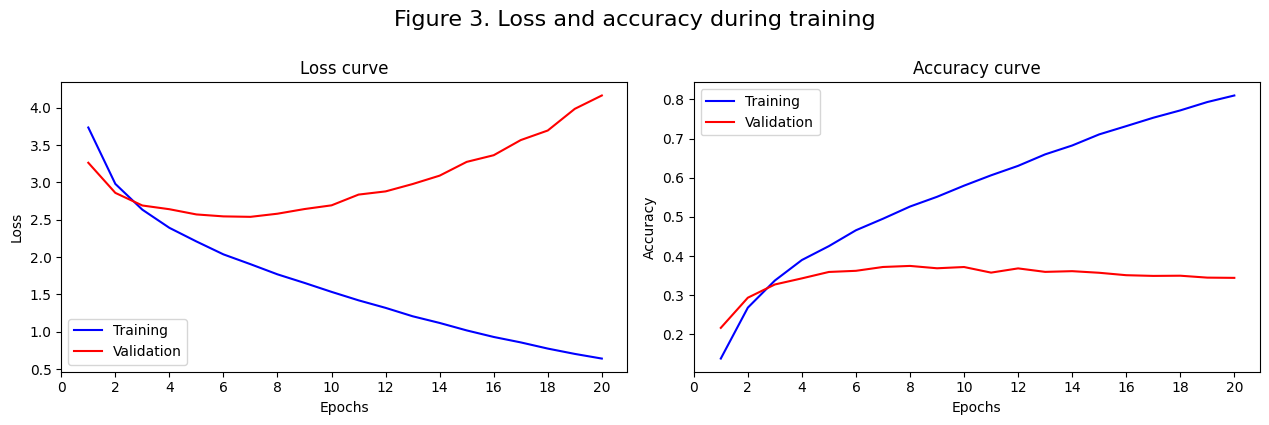

In [15]:
# Visualize training loss and accuracy
train_loss, train_acc, val_loss, val_acc = read_train_stats("baselineCNN")

plt.figure(figsize=(12.8, 4.2))
plt.suptitle(
    "Figure 3. Loss and accuracy during training",
    fontsize=16,
    y=1.,
)
plt.subplot(1, 2, 1)
plt.plot(list(range(1, 21)), train_loss, label="Training", color="blue")
plt.plot(list(range(1, 21)), val_loss, label="Validation", color="red")
plt.legend()
plt.title("Loss curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(np.linspace(0, 20, 11))

plt.subplot(1, 2, 2)
plt.plot(list(range(1, 21)), train_acc, label="Training", color="blue")
plt.plot(list(range(1, 21)), val_acc, label="Validation", color="red")
plt.legend()
plt.title("Accuracy curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(np.linspace(0, 20, 11))

plt.tight_layout()
plt.show()



In [16]:
# Computing testing performance
y_test, y_pred = read_test_results("baselineCNN")

'''
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(20, 20))
display = ConfusionMatrixDisplay(cm, display_labels=test_data.classes)
display.plot(cmap="Greens", ax=ax)
plt.show()
'''
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
print(f"Performance in testing set:")
print(f"Accuracy: {'{:.4f}'.format(accuracy)}\nPrecision: {'{:.4f}'.format(precision)}\nRecall: {'{:.4f}'.format(recall)}")


Performance in testing set:
Accuracy: 0.3474
Precision: 0.3581
Recall: 0.3474


## Performance Analyse
• loss, accuracy, confusion matrix and other relevant metrics

As shown in Figure 3, the training loss and accuracy improve at a slightly decreasing rate, indicating steady convergence on the training set. However, the validation loss and accuracy worsen at an early stage, starting from epoch 7-8. This significantly indicates overfitting in the baseline CNN model. Such a result is foreseeable, given that there are 100 classes in total, but each class contains only 400 images as training data after partitioning 100 images for the validation set. It is challenging for a baseline CNN model to learn generalized features from such a limited training dataset.
<br></br>
Considering the inefficiency of visualizing a confusion matrix with a large number of classes (100), we decided to compute weighted scores to assess the performance on the test set. The low accuracy of 0.3474 is consistent with the validation accuracy at the final epoch, while a slightly higher precision (0.3581) compared to the recall (0.3474) suggests that the model is more prone to producing False Negatives than False Positives.


# **Tuning hyperparam in baseline**

## Basic illustration
The fine-tuning stage focuses on three hyperparameters: (i) the output-channel width of the first convolutional layer, (ii) the number of units in the hidden layer of the fully connected classifier, and (iii) whether a third convolutional layer is present. For the first two, each hyperparameter is varied over {half, one, two} × its default value — 16, 32 and 64 channels, and 64, 128 and 256 hidden units — so that both a decrease and an increase relative to the default are covered.
<br></br>
Note that adding the third convolutional layer also doubles the number of channels at that stage, so the final feature map carries four times the channel width of the first layer.

In [2]:
# parameters
conv_layer_depth = [16, 32, 64]
hidden_layer_size = [64, 128, 256]
extra_conv = [False, True]

In [17]:
img_shape = train_data[0][0].shape
save_path = '/content/drive/MyDrive/ARIN5101/models'

for c, h, extra in list(product(conv_layer_depth, hidden_layer_size, extra_conv)):
  print("=" * 40)
  # set up resuming mechanism to handle potential disconnection in google colab
  path = f"{save_path}/baseline_CNN_ft_[{c}_{h}_{extra}].pth"
  if os.path.isfile(path):
    print(f"Skipping existing CNN with parameters: conv layer depth = {c}, hidden layer size = {h}, extra conv = {extra}.")
    continue

  # Train and validation
  print(f"Training CNN with parameters: conv layer depth = {c}, hidden layer size = {h}, extra conv = {extra}.")

  set_seed(seed)
  g = torch.Generator().manual_seed(seed)

  train_loader = DataLoader(splitted_train_data, batch_size=batch_size, shuffle=True, generator=g)
  val_loader   = DataLoader(splitted_val_data, batch_size=batch_size, shuffle=False)

  baseCNN_ft_model = baselineCNN(
      in_channel=img_shape[0],
      in_size=img_shape[1],
      num_class=len(train_data.classes),
      conv_layer_depth=c,
      hidden_layer_size=h,
      extra_conv=extra
  ).to(device)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = optim.Adam(baseCNN_ft_model.parameters(), lr=0.001)
  start = time.time()
  baseCNN_ft_model = train(baseCNN_ft_model, loss_fn, optimizer, train_loader, val_loader, f"baseline_CNN_ft_[{c}_{h}_{extra}]")

  # save the model so that we do not need to train again
  os.makedirs(save_path, exist_ok=True)
  torch.save(baseCNN_ft_model.state_dict(), f"{save_path}/baseline_CNN_ft_[{c}_{h}_{extra}].pth")
  print(f"total time spent to train and save a model: {time.time()-start}s")

Training CNN with parameters: conv layer depth = 16, hidden layer size = 64, extra conv = False.
Epoch 1: Training loss = 3.868964849090576, accuracy = 0.119225; Validation loss = 3.3965040008544922, accuracy = 0.1887
Epoch 2: Training loss = 3.1711865699768067, accuracy = 0.2318; Validation loss = 3.066843296432495, accuracy = 0.2512
Epoch 3: Training loss = 2.87323424949646, accuracy = 0.28905; Validation loss = 2.897861611175537, accuracy = 0.2859
Epoch 4: Training loss = 2.670955504608154, accuracy = 0.3309; Validation loss = 2.779225735092163, accuracy = 0.3117
Epoch 5: Training loss = 2.5246829460144045, accuracy = 0.358175; Validation loss = 2.756515626525879, accuracy = 0.3138
Epoch 6: Training loss = 2.4026800552368166, accuracy = 0.3854; Validation loss = 2.6929104316711427, accuracy = 0.3278
Epoch 7: Training loss = 2.306919321060181, accuracy = 0.40495; Validation loss = 2.6471107315063476, accuracy = 0.3408
Epoch 8: Training loss = 2.2158650299072264, accuracy = 0.42615; V

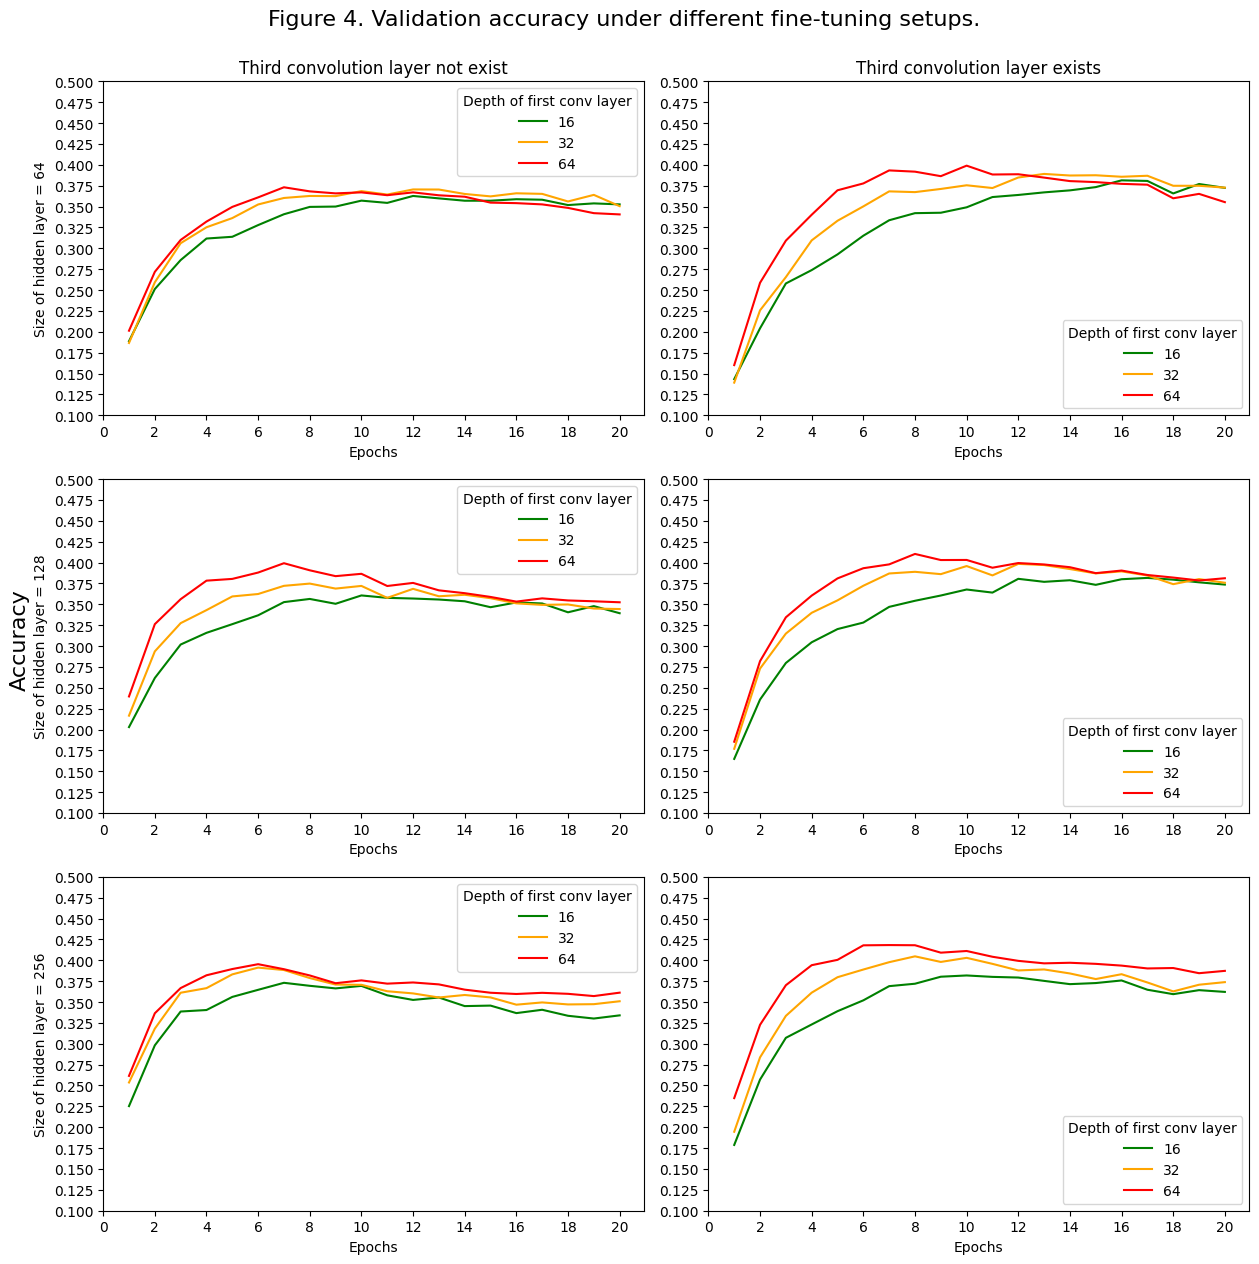

In [25]:
# visualize by validation accuracy
color = ["green", "orange", "red"]
fig = plt.figure(figsize=(12.8, 12.6))

fig.suptitle(
    "Figure 4. Validation accuracy under different fine-tuning setups.",
    fontsize=16,
    y=1.0,
)

fig.supylabel(
    "Accuracy",
    fontsize=16,
)

for idx_h, h in enumerate(hidden_layer_size):
  for idx_e, extra in enumerate(extra_conv):
    plt.subplot(3, 2, (idx_h*2)+idx_e+1)
    if idx_h == 0:
      plt.title(f"Third convolution layer {'exists' if extra else 'not exist'}")
    if not extra:
      plt.ylabel(f"Size of hidden layer = {h}")
    for idx_c, c in enumerate(conv_layer_depth):
      _, _, _, val_acc = read_train_stats(f"baseline_CNN_ft_[{c}_{h}_{extra}]")
      plt.plot(list(range(1, 21)), val_acc, label=f"{c}", color=color[idx_c])
      plt.xlabel("Epochs")
      plt.xticks(np.linspace(0, 20, 11))
      plt.ylim(0.1, 0.5)
      plt.yticks(np.linspace(0.1, 0.5, 17))
    plt.legend(title="Depth of first conv layer")

plt.tight_layout()
plt.show()

## Performance Analyse
• Comparisons among the combinations using relevant metrics

To keep the comparison on a single, consistent metric, the fine-tuning stage is evaluated solely by validation accuracy. Figure 4 shows validation accuracy for all 18 configurations: within each panel, the three curves correspond to the three channel widths of the first convolutional layer (16, 32 and 64); the three rows correspond to the hidden-layer sizes (64, 128 and 256); and the two columns show the model without and with the third convolutional layer.
<br></br>
Regarding the channel width of the first convolutional layer, when the hidden layer is smallest (64 units), the widest setting (64 channels) takes an early lead but is overtaken later in training. For the two larger hidden layers (128 and 256), the widest setting maintains its lead throughout. The narrowest setting (16 channels) is consistently worse than the intermediate one (32) in every panel. This suggests that a wider first layer gives the model more capacity to represent the data, but that this capacity can only be exploited when the classifier is large enough to make use of it; otherwise the additional features do not translate into better predictions.
<br></br>
Regarding the hidden-layer size, increasing the number of hidden units slightly raises the peak validation accuracy, which is consistent with a stronger classifier improving performance.
<br></br>
Regarding the third convolutional layer, its presence raises the peak validation accuracy and delays the onset of the subsequent decline. This suggests that the additional layer supplies the classifier with more abstract, more global features and thereby mitigates overfitting to some extent.
<br></br>
Although the best fine-tuned configuration does outperform the baseline (the orange curve in the second row, first column), the improvement is marginal: the peak validation accuracy rises from about 0.375 to 0.42. All configurations nevertheless overfit to different degrees within the 20 training epochs.

# **CNN model with improvement A**

## Basic illustration

In [ ]:
# Not Implemented Yet

## Performance Analyse
• Comparisons among the combinations using relevant metrics

# **CNN model with improvement B**

## Basic illustration

In [ ]:
# Not Implemented Yet

## Performance Analyse
• Comparisons among the combinations using relevant metrics

# **CNN model with improvements A and B**

## Basic illustration

In [ ]:
# Not Implemented Yet

## Performance Analyse
• Comparisons among the combinations using relevant metrics

# **Final model summary and reflections**

In [ ]:
# any visualization

• Which one is the best performing model and why

• Higher accuracy does not necessarily indicate a better model